In [56]:
import gymnasium as gym
import numpy as np
import minigrid
import matplotlib.pyplot as plt
from collections import defaultdict

100
0


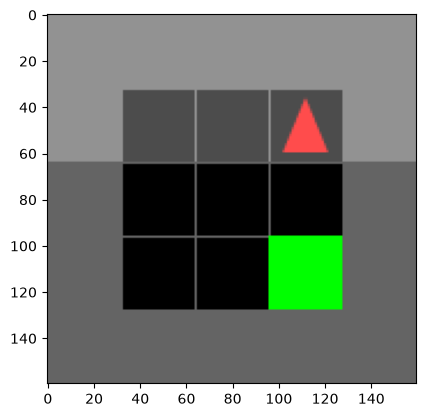

In [57]:
env = gym.make("MiniGrid-Empty-5x5-v0", render_mode = "rgb_array")


steps = 0
done = False
obs, info = env.reset()
while not done:
    action = env.action_space.sample()
    next_obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    obs = next_obs
    steps += 1
plt.imshow(env.render())
print(steps)
print(reward)


In [ ]:
obs.keys()

In [17]:
obs["direction"], obs["mission"]

(0, 'get to the green goal square')

In [18]:
obs["image"].shape

(7, 7, 3)

In [48]:
obs["image"][:,:,0].T

array([[2, 2, 2, 2, 2, 2, 2],
       [2, 2, 2, 2, 2, 2, 2],
       [2, 2, 2, 2, 2, 2, 2],
       [2, 2, 2, 2, 2, 2, 2],
       [2, 2, 2, 2, 2, 2, 2],
       [2, 2, 2, 1, 1, 8, 2],
       [2, 2, 2, 1, 1, 1, 2]], dtype=uint8)

In [23]:
obs, reward, terminated, truncated, info = env.step(1)

In [26]:
print(env.unwrapped.agent_dir)

1


In [27]:
env.action_space

Discrete(7)

In [29]:
list(env.unwrapped.actions)

[<Actions.left: 0>,
 <Actions.right: 1>,
 <Actions.forward: 2>,
 <Actions.pickup: 3>,
 <Actions.drop: 4>,
 <Actions.toggle: 5>,
 <Actions.done: 6>]

In [55]:
n_actions = 3
Q = defaultdict(lambda: np.zeros(n_actions))
alpha = 0.1
gamma = 0.99
epsilon = 1.0
n_episodes = 5000
rewards = []

for episode in range(n_episodes):
    obs, info = env.reset()
    state = (tuple(env.unwrapped.agent_pos), env.unwrapped.agent_dir)
    done = False
    while not done:
        if np.random.random() < epsilon:
            action = np.random.randint(n_actions)
        else:
            action = np.argmax(Q[state])

        next_obs, reward, terminated, truncated, info = env.step(action)
        next_state = (tuple(env.unwrapped.agent_pos), env.unwrapped.agent_dir)

        if terminated:
            target = reward

        else:
            target = reward + gamma * np.max(Q[next_state])

        Q[state][action] = Q[state][action] + alpha * (target - Q[state][action])

        done = terminated or truncated
        state = next_state

    rewards.append(reward)

    epsilon = max(0.01, epsilon * 0.999)

print(np.mean(rewards[-100:]))


            


0.9541
